In [1]:
from google.colab import files

uploaded = files.upload()

Saving customer_support_tickets.csv to customer_support_tickets.csv


In [2]:
import pandas as pd

# Load the dataset
df = pd.read_csv("customer_support_tickets.csv")

# Display the first 5 rows
display(df.head())

# Check the number of rows and columns
print("Dataset shape:", df.shape)

# Display all column names
print("\nColumn names:")
print(df.columns.tolist())

# Check dataset information
df.info()

,Ticket ID,Customer Name,Customer Email,Customer Age,Customer Gender,Product Purchased,Date of Purchase,Ticket Type,Ticket Subject,Ticket Description,Ticket Status,Resolution,Ticket Priority,Ticket Channel,First Response Time,Time to Resolution,Customer Satisfaction Rating
0,1,Marisa Obrien,carrollallison@example.com,32,Other,GoPro Hero,2021-03-22,Technical issue,Product setup,I'm having an issue with the {product_purchase...,Pending Customer Response,NaN,Critical,Social media,2023-06-01 12:15:36,NaN,NaN
1,2,Jessica Rios,clarkeashley@example.com,42,Female,LG Smart TV,2021-05-22,Technical issue,Peripheral compatibility,I'm having an issue with the {product_purchase...,Pending Customer Response,NaN,Critical,Chat,2023-06-01 16:45:38,NaN,NaN
2,3,Christopher Robbins,gonzalestracy@example.com,48,Other,Dell XPS,2020-07-14,Technical issue,Network problem,I'm facing a problem with my {product_purchase...,Closed,Case maybe show recently my computer follow.,Low,Social media,2023-06-01 11:14:38,2023-06-01 18:05:38,3.0
3,4,Christina Dillon,bradleyolson@example.org,27,Female,Microsoft Office,2020-11-13,Billing inquiry,Account access,I'm having an issue with the {product_purchase...,Closed,Try capital clearly never color toward story.,Low,Social media,2023-06-01 07:29:40,2023-06-01 01:57:40,3.0
4,5,Alexander Carroll,bradleymark@example.com,67,Female,Autodesk AutoCAD,2020-02-04,Billing inquiry,Data loss,I'm having an issue with the {product_purchase...,Closed,West decision evidence bit.,Low,Email,2023-06-01 00:12:42,2023-06-01 19:53:42,1.0


Dataset shape: (8469, 17)

Column names:
['Ticket ID', 'Customer Name', 'Customer Email', 'Customer Age', 'Customer Gender', 'Product Purchased', 'Date of Purchase', 'Ticket Type', 'Ticket Subject', 'Ticket Description', 'Ticket Status', 'Resolution', 'Ticket Priority', 'Ticket Channel', 'First Response Time', 'Time to Resolution', 'Customer Satisfaction Rating']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8469 entries, 0 to 8468
Data columns (total 17 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Ticket ID                     8469 non-null   int64  
 1   Customer Name                 8469 non-null   object 
 2   Customer Email                8469 non-null   object 
 3   Customer Age                  8469 non-null   int64  
 4   Customer Gender               8469 non-null   object 
 5   Product Purchased             8469 non-null   object 
 6   Date of Purchase              8469 non-null   obje

In [3]:
# Check missing values
print("Missing values in each column:")
print(df.isnull().sum())

# Check duplicate records
print("\nNumber of duplicate rows:", df.duplicated().sum())

# Check ticket categories
print("\nTicket Type Distribution:")
print(df["Ticket Type"].value_counts())

# Check ticket priorities
print("\nTicket Priority Distribution:")
print(df["Ticket Priority"].value_counts())

# Check unique labels
print("\nUnique Ticket Types:")
print(df["Ticket Type"].unique())

print("\nUnique Ticket Priorities:")
print(df["Ticket Priority"].unique())

Missing values in each column:
Ticket ID                          0
Customer Name                      0
Customer Email                     0
Customer Age                       0
Customer Gender                    0
Product Purchased                  0
Date of Purchase                   0
Ticket Type                        0
Ticket Subject                     0
Ticket Description                 0
Ticket Status                      0
Resolution                      5700
Ticket Priority                    0
Ticket Channel                     0
First Response Time             2819
Time to Resolution              5700
Customer Satisfaction Rating    5700
dtype: int64

Number of duplicate rows: 0

Ticket Type Distribution:
Ticket Type
Refund request          1752
Technical issue         1747
Cancellation request    1695
Product inquiry         1641
Billing inquiry         1634
Name: count, dtype: int64

Ticket Priority Distribution:
Ticket Priority
Medium      2192
Critical    2129
High   

In [4]:
# Combine ticket subject and description
df["Ticket Text"] = (
    df["Ticket Subject"].astype(str) + " " +
    df["Ticket Description"].astype(str)
)

# Convert text to lowercase
df["Ticket Text"] = df["Ticket Text"].str.lower()

# Remove unnecessary spaces
df["Ticket Text"] = df["Ticket Text"].str.strip()

# Display the prepared text
print("Prepared ticket text:")
display(df[["Ticket Subject", "Ticket Description", "Ticket Text"]].head())

# Check for missing values in the new column
print("\nMissing values in Ticket Text:",
      df["Ticket Text"].isnull().sum())

Prepared ticket text:


,Ticket Subject,Ticket Description,Ticket Text
0,Product setup,I'm having an issue with the {product_purchase...,product setup i'm having an issue with the {pr...
1,Peripheral compatibility,I'm having an issue with the {product_purchase...,peripheral compatibility i'm having an issue w...
2,Network problem,I'm facing a problem with my {product_purchase...,network problem i'm facing a problem with my {...
3,Account access,I'm having an issue with the {product_purchase...,account access i'm having an issue with the {p...
4,Data loss,I'm having an issue with the {product_purchase...,data loss i'm having an issue with the {produc...



Missing values in Ticket Text: 0


In [5]:
import re
import nltk
from nltk.corpus import stopwords

# Download English stopwords
nltk.download("stopwords")

# Load stopwords
stop_words = set(stopwords.words("english"))

# Function to clean text
def clean_text(text):
    text = text.lower()

    # Remove punctuation and special characters
    text = re.sub(r"[^a-zA-Z\s]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    # Remove stopwords
    words = text.split()
    words = [word for word in words if word not in stop_words]

    return " ".join(words)

# Apply text cleaning
df["Cleaned Text"] = df["Ticket Text"].apply(clean_text)

# Display original and cleaned text
display(df[["Ticket Text", "Cleaned Text"]].head())

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


,Ticket Text,Cleaned Text
0,product setup i'm having an issue with the {pr...,product setup issue product purchased please a...
1,peripheral compatibility i'm having an issue w...,peripheral compatibility issue product purchas...
2,network problem i'm facing a problem with my {...,network problem facing problem product purchas...
3,account access i'm having an issue with the {p...,account access issue product purchased please ...
4,data loss i'm having an issue with the {produc...,data loss issue product purchased please assis...


In [6]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Create TF-IDF vectorizer
tfidf = TfidfVectorizer(max_features=5000)

# Convert cleaned text into numerical features
X = tfidf.fit_transform(df["Cleaned Text"])

# Display the shape of the TF-IDF matrix
print("TF-IDF matrix shape:", X.shape)

# Display the number of words/features
print("Number of TF-IDF features:", len(tfidf.get_feature_names_out()))

# Display some extracted words
print("\nSample features:")
print(tfidf.get_feature_names_out()[:20])

TF-IDF matrix shape: (8469, 5000)
Number of TF-IDF features: 5000

Sample features:
['ab' 'ability' 'able' 'absolutely' 'abundance' 'abuse' 'acc' 'accept'
 'accepted' 'accepting' 'accepts' 'access' 'accessed' 'accessible'
 'accessing' 'accessories' 'accessory' 'accident' 'accidentally'
 'accompanied']


In [7]:
from sklearn.model_selection import train_test_split

# Define target variables
y_category = df["Ticket Type"]
y_priority = df["Ticket Priority"]

# Split data for category classification
X_train_cat, X_test_cat, y_train_cat, y_test_cat = train_test_split(
    X, y_category,
    test_size=0.20,
    random_state=42,
    stratify=y_category
)

# Split data for priority classification
X_train_pri, X_test_pri, y_train_pri, y_test_pri = train_test_split(
    X, y_priority,
    test_size=0.20,
    random_state=42,
    stratify=y_priority
)

# Display dataset sizes
print("CATEGORY CLASSIFICATION")
print("Training samples:", X_train_cat.shape[0])
print("Testing samples:", X_test_cat.shape[0])

print("\nPRIORITY CLASSIFICATION")
print("Training samples:", X_train_pri.shape[0])
print("Testing samples:", X_test_pri.shape[0])

CATEGORY CLASSIFICATION
Training samples: 6775
Testing samples: 1694

PRIORITY CLASSIFICATION
Training samples: 6775
Testing samples: 1694


In [8]:
from sklearn.linear_model import LogisticRegression

# Create category classification model
category_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model
category_model.fit(X_train_cat, y_train_cat)

print("Category classification model trained successfully!")

Category classification model trained successfully!


In [9]:
# Create priority classification model
priority_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model
priority_model.fit(X_train_pri, y_train_pri)

print("Priority classification model trained successfully!")

Priority classification model trained successfully!


In [10]:
from sklearn.metrics import accuracy_score, classification_report

# Make predictions
category_predictions = category_model.predict(X_test_cat)
priority_predictions = priority_model.predict(X_test_pri)

# Evaluate category model
print("========== CATEGORY CLASSIFICATION ==========")

print("Accuracy:",
      accuracy_score(y_test_cat, category_predictions))

print("\nClassification Report:")
print(classification_report(y_test_cat, category_predictions))

# Evaluate priority model
print("\n========== PRIORITY CLASSIFICATION ==========")

print("Accuracy:",
      accuracy_score(y_test_pri, priority_predictions))

print("\nClassification Report:")
print(classification_report(y_test_pri, priority_predictions))

========== CATEGORY CLASSIFICATION ==========
Accuracy: 0.20365997638724911

Classification Report:
                      precision    recall  f1-score   support

     Billing inquiry       0.18      0.16      0.17       327
Cancellation request       0.18      0.20      0.19       339
     Product inquiry       0.22      0.21      0.22       328
      Refund request       0.22      0.22      0.22       351
     Technical issue       0.21      0.22      0.22       349

            accuracy                           0.20      1694
           macro avg       0.20      0.20      0.20      1694
        weighted avg       0.20      0.20      0.20      1694


========== PRIORITY CLASSIFICATION ==========
Accuracy: 0.2615112160566706

Classification Report:
              precision    recall  f1-score   support

    Critical       0.25      0.24      0.25       426
        High       0.27      0.25      0.26       417
         Low       0.25      0.26      0.26       413
      Medium       0.2

In [11]:
# Display 15 actual ticket examples
pd.set_option("display.max_colwidth", 150)

display(
    df[[
        "Ticket Type",
        "Ticket Priority",
        "Ticket Subject",
        "Ticket Description"
    ]].sample(15, random_state=42)
)

,Ticket Type,Ticket Priority,Ticket Subject,Ticket Description
4830,Refund request,High,Product setup,I'm having an issue with the {product_purchased}. Please assist. I'm using xda-developer for something different. If there are issues with the {pr...
7075,Product inquiry,Low,Battery life,"I'm having trouble connecting my {product_purchased} to my home Wi-Fi network. It doesn't detect any networks, although other devices are connecti..."
4715,Billing inquiry,Low,Refund request,I'm having an issue with the {product_purchased}. Please assist.\n\nPlease give credit to: @joeyclay I'm concerned about the security of my {produ...
2022,Billing inquiry,High,Peripheral compatibility,I'm having an issue with the {product_purchased}. Please assist.\n\n4. Check and compare product pricing\n\nYou will see that prices are based on ...
676,Refund request,Medium,Peripheral compatibility,I'm having an issue with the {product_purchased}. Please assist.\n\nI would like my price to rise so that I can return it.\n\nPlease notify me if ...
2283,Refund request,Low,Refund request,I've encountered a data loss issue with my {product_purchased}. All the files and documents seem to have disappeared. Can you guide me on how to r...
5076,Product inquiry,Medium,Software bug,I'm having an issue with the {product_purchased}. Please assist. I've noticed a peculiar error message popping up on my {product_purchased} screen...
2476,Refund request,High,Installation support,I'm having an issue with the {product_purchased}. Please assist.\n\nIf you are having trouble with your package you need to contact customer servi...
6847,Refund request,High,Hardware issue,"I'm encountering a software bug in the {product_purchased}. Whenever I try to perform a specific action, the application crashes. Are there any up..."
511,Product inquiry,Low,Battery life,"I'm having an issue with the {product_purchased}. Please assist.\n\nThanks, and thanks a lot, I've tried clearing the cache and data for the {prod..."


In [12]:
# Check how ticket subjects relate to ticket categories
print("Ticket Subject and Ticket Type relationship:")

display(pd.crosstab(
    df["Ticket Subject"],
    df["Ticket Type"]
))

# Check category and priority combinations
print("\nTicket Type and Ticket Priority relationship:")

display(pd.crosstab(
    df["Ticket Type"],
    df["Ticket Priority"]
))

Ticket Subject and Ticket Type relationship:


Ticket Type,Billing inquiry,Cancellation request,Product inquiry,Refund request,Technical issue
Ticket Subject,,,,,
Account access,103,92,107,108,99
Battery life,106,104,101,119,112
Cancellation request,82,103,85,109,108
Data loss,89,115,91,97,99
Delivery problem,115,114,109,107,116
Display issue,91,103,80,99,105
Hardware issue,100,109,106,129,103
Installation support,108,99,99,119,105
Network problem,95,102,113,107,122



Ticket Type and Ticket Priority relationship:


Ticket Priority,Critical,High,Low,Medium
Ticket Type,,,,
Billing inquiry,420,382,398,434
Cancellation request,423,398,414,460
Product inquiry,403,399,398,441
Refund request,444,448,440,420
Technical issue,439,458,413,437


In [13]:
# Check the number of unique ticket descriptions
print("Total tickets:", len(df))

print("Unique ticket subjects:",
      df["Ticket Subject"].nunique())

print("Unique ticket descriptions:",
      df["Ticket Description"].nunique())

print("Unique combined ticket texts:",
      df["Ticket Text"].nunique())

# Display the most common ticket subjects
print("\nMost common ticket subjects:")
print(df["Ticket Subject"].value_counts().head(15))

# Display the most common ticket descriptions
print("\nMost common ticket descriptions:")
print(df["Ticket Description"].value_counts().head(10))

Total tickets: 8469
Unique ticket subjects: 16
Unique ticket descriptions: 8077
Unique combined ticket texts: 8325

Most common ticket subjects:
Ticket Subject
Refund request              576
Software bug                574
Product compatibility       567
Delivery problem            561
Hardware issue              547
Battery life                542
Network problem             539
Installation support        530
Product setup               529
Payment issue               526
Product recommendation      517
Account access              509
Peripheral compatibility    496
Data loss                   491
Cancellation request        487
Name: count, dtype: int64

Most common ticket descriptions:
Ticket Description
I'm having an issue with the {product_purchased}. Please assist. I need assistance as soon as possible because it's affecting my work and productivity.                                                         25
I'm having an issue with the {product_purchased}. Please assist. This 

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

# Prepare category classification data
X_text = df["Cleaned Text"]
y = df["Ticket Type"]

# Split the original text data
X_train, X_test, y_train, y_test = train_test_split(
    X_text,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Define algorithms
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Linear SVM": LinearSVC(random_state=42),
    "Naive Bayes": MultinomialNB()
}

# Store results
results = []

# Train and evaluate each model
for name, model in models.items():

    pipeline = Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=10000,
            ngram_range=(1, 2),
            sublinear_tf=True
        )),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, average="macro"),
        "Recall": recall_score(y_test, predictions, average="macro"),
        "F1-Score": f1_score(y_test, predictions, average="macro")
    })

# Display comparison
results_df = pd.DataFrame(results)

print("CATEGORY CLASSIFICATION MODEL COMPARISON")
display(results_df.round(4))

CATEGORY CLASSIFICATION MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.2102,0.2097,0.2098,0.2096
1,Linear SVM,0.2037,0.2042,0.2037,0.2038
2,Naive Bayes,0.2137,0.2124,0.2117,0.2067


In [15]:
# Prepare priority classification data
X_text = df["Cleaned Text"]
y = df["Ticket Priority"]

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X_text,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Define models
priority_models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, random_state=42
    ),
    "Linear SVM": LinearSVC(random_state=42),
    "Naive Bayes": MultinomialNB()
}

priority_results = []

# Train and evaluate
for name, model in priority_models.items():

    pipeline = Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=10000,
            ngram_range=(1, 2),
            sublinear_tf=True
        )),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    priority_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, average="macro"
        ),
        "Recall": recall_score(
            y_test, predictions, average="macro"
        ),
        "F1-Score": f1_score(
            y_test, predictions, average="macro"
        )
    })

# Display results
priority_results_df = pd.DataFrame(priority_results)

print("PRIORITY CLASSIFICATION MODEL COMPARISON")
display(priority_results_df.round(4))

PRIORITY CLASSIFICATION MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.2568,0.2566,0.2562,0.2558
1,Linear SVM,0.2450,0.2445,0.2447,0.2445
2,Naive Bayes,0.2586,0.2568,0.2570,0.2531


In [16]:
# Import mutual information metric
from sklearn.metrics import mutual_info_score

# 1. Relationship between ticket subject and category
print("TICKET SUBJECT vs TICKET TYPE")
display(pd.crosstab(
    df["Ticket Subject"],
    df["Ticket Type"],
    normalize="index"
).round(2))

# 2. Relationship between ticket subject and priority
print("\nTICKET SUBJECT vs TICKET PRIORITY")
display(pd.crosstab(
    df["Ticket Subject"],
    df["Ticket Priority"],
    normalize="index"
).round(2))

# 3. Relationship between category and priority
print("\nTICKET TYPE vs TICKET PRIORITY")
display(pd.crosstab(
    df["Ticket Type"],
    df["Ticket Priority"],
    normalize="index"
).round(2))

# 4. Measure label relationships
print("\nMUTUAL INFORMATION SCORES")

print(
    "Subject and category:",
    round(mutual_info_score(
        df["Ticket Subject"], df["Ticket Type"]
    ), 4)
)

print(
    "Subject and priority:",
    round(mutual_info_score(
        df["Ticket Subject"], df["Ticket Priority"]
    ), 4)
)

print(
    "Category and priority:",
    round(mutual_info_score(
        df["Ticket Type"], df["Ticket Priority"]
    ), 4)
)

# 5. Check whether identical descriptions have conflicting labels
description_groups = df.groupby("Ticket Description").agg(
    Number_of_Tickets=("Ticket ID", "count"),
    Category_Count=("Ticket Type", "nunique"),
    Priority_Count=("Ticket Priority", "nunique")
)

print("\nDescriptions appearing with multiple categories:")
print((description_groups["Category_Count"] > 1).sum())

print("\nDescriptions appearing with multiple priorities:")
print((description_groups["Priority_Count"] > 1).sum())

TICKET SUBJECT vs TICKET TYPE


Ticket Type,Billing inquiry,Cancellation request,Product inquiry,Refund request,Technical issue
Ticket Subject,,,,,
Account access,0.20,0.18,0.21,0.21,0.19
Battery life,0.20,0.19,0.19,0.22,0.21
Cancellation request,0.17,0.21,0.17,0.22,0.22
Data loss,0.18,0.23,0.19,0.20,0.20
Delivery problem,0.20,0.20,0.19,0.19,0.21
Display issue,0.19,0.22,0.17,0.21,0.22
Hardware issue,0.18,0.20,0.19,0.24,0.19
Installation support,0.20,0.19,0.19,0.22,0.20
Network problem,0.18,0.19,0.21,0.20,0.23



TICKET SUBJECT vs TICKET PRIORITY


Ticket Priority,Critical,High,Low,Medium
Ticket Subject,,,,
Account access,0.22,0.26,0.26,0.27
Battery life,0.23,0.25,0.25,0.28
Cancellation request,0.26,0.24,0.24,0.25
Data loss,0.26,0.26,0.22,0.25
Delivery problem,0.23,0.27,0.23,0.28
Display issue,0.25,0.25,0.23,0.26
Hardware issue,0.28,0.24,0.28,0.20
Installation support,0.24,0.27,0.24,0.25
Network problem,0.26,0.24,0.24,0.25



TICKET TYPE vs TICKET PRIORITY


Ticket Priority,Critical,High,Low,Medium
Ticket Type,,,,
Billing inquiry,0.26,0.23,0.24,0.27
Cancellation request,0.25,0.23,0.24,0.27
Product inquiry,0.25,0.24,0.24,0.27
Refund request,0.25,0.26,0.25,0.24
Technical issue,0.25,0.26,0.24,0.25



MUTUAL INFORMATION SCORES
Subject and category: 0.0023
Subject and priority: 0.0025
Category and priority: 0.0006

Descriptions appearing with multiple categories:
42

Descriptions appearing with multiple priorities:
41


In [17]:
# Check relationships between other features and targets

features = [
    "Product Purchased",
    "Customer Gender",
    "Ticket Channel",
    "Ticket Status",
    "Customer Age"
]

print("FEATURE RELATIONSHIPS WITH TICKET TYPE AND PRIORITY")

for feature in features:
    print("\n====================================")
    print("Feature:", feature)

    print("\nRelationship with Ticket Type:")
    print(round(
        mutual_info_score(df[feature], df["Ticket Type"]), 4
    ))

    print("Relationship with Ticket Priority:")
    print(round(
        mutual_info_score(df[feature], df["Ticket Priority"]), 4
    ))

# Check conflicting labels for identical descriptions
description_groups = df.groupby("Ticket Description").agg(
    Category_Count=("Ticket Type", "nunique"),
    Priority_Count=("Ticket Priority", "nunique")
)

print("\nDescriptions with multiple categories:",
      (description_groups["Category_Count"] > 1).sum())

print("Descriptions with multiple priorities:",
      (description_groups["Priority_Count"] > 1).sum())

FEATURE RELATIONSHIPS WITH TICKET TYPE AND PRIORITY

Feature: Product Purchased

Relationship with Ticket Type:
0.0082
Relationship with Ticket Priority:
0.0079

Feature: Customer Gender

Relationship with Ticket Type:
0.0003
Relationship with Ticket Priority:
0.0003

Feature: Ticket Channel

Relationship with Ticket Type:
0.0007
Relationship with Ticket Priority:
0.0009

Feature: Ticket Status

Relationship with Ticket Type:
0.0005
Relationship with Ticket Priority:
0.0005

Feature: Customer Age

Relationship with Ticket Type:
0.0132
Relationship with Ticket Priority:
0.0085

Descriptions with multiple categories: 42
Descriptions with multiple priorities: 41


In [18]:
# Find descriptions that have more than one category or priority

conflicting_descriptions = df.groupby("Ticket Description").agg(
    Category_Count=("Ticket Type", "nunique"),
    Priority_Count=("Ticket Priority", "nunique"),
    Categories=("Ticket Type", lambda x: list(x.unique())),
    Priorities=("Ticket Priority", lambda x: list(x.unique())),
    Number_of_Tickets=("Ticket ID", "count")
).reset_index()

# Keep only descriptions with conflicting labels
conflicting_descriptions = conflicting_descriptions[
    (conflicting_descriptions["Category_Count"] > 1) |
    (conflicting_descriptions["Priority_Count"] > 1)
]

# Display 10 examples
print("Number of conflicting descriptions:",
      len(conflicting_descriptions))

display(conflicting_descriptions.head(10))

Number of conflicting descriptions: 44


,Ticket Description,Category_Count,Priority_Count,Categories,Priorities,Number_of_Tickets
482,I'm facing issues logging into my {product_purchased} account. It says my account is locked. What should I do to unlock it? I'm worried that the i...,2,2,"[Cancellation request, Product inquiry]","[Low, High]",2
1770,I'm having an issue with the {product_purchased}. Please assist.\n\nI'm having an issue with the {product_purchased}. Please assist.\n\nI'm having...,1,2,[Product inquiry],"[Critical, Low]",2
1771,I'm having an issue with the {product_purchased}. Please assist.\n\nI'm having an issue with the {product_purchased}. Please assist.\n\nI'm having...,2,2,"[Product inquiry, Billing inquiry]","[Critical, High]",2
1776,I'm having an issue with the {product_purchased}. Please assist.\n\nI'm having an issue with the {product_purchased}. Please assist.\n\nI'm having...,3,2,"[Refund request, Billing inquiry, Technical issue]","[Low, Medium]",3
2767,I'm having an issue with the {product_purchased}. Please assist.\n\nThanks. I'm concerned about the security of my {product_purchased} and would l...,2,2,"[Technical issue, Cancellation request]","[Low, High]",2
4347,I'm having an issue with the {product_purchased}. Please assist. I need assistance as soon as possible because it's affecting my work and producti...,5,4,"[Product inquiry, Cancellation request, Refund request, Billing inquiry, Technical issue]","[Critical, High, Medium, Low]",25
4359,"I'm having an issue with the {product_purchased}. Please assist. I rely heavily on my {product_purchased} for my daily tasks, and this issue is hi...",5,4,"[Technical issue, Cancellation request, Product inquiry, Refund request, Billing inquiry]","[Medium, Critical, High, Low]",15
4451,I'm having an issue with the {product_purchased}. Please assist. I'm concerned about the security of my {product_purchased} and would like to ensu...,5,4,"[Technical issue, Refund request, Billing inquiry, Cancellation request, Product inquiry]","[Low, Critical, High, Medium]",25
4454,"I'm having an issue with the {product_purchased}. Please assist. I'm experiencing this issue on multiple devices of the same model, so it seems to...",5,4,"[Refund request, Technical issue, Cancellation request, Billing inquiry, Product inquiry]","[Medium, Critical, High, Low]",12
4503,I'm having an issue with the {product_purchased}. Please assist. I'm not sure if this issue is specific to my device or if others have reported si...,5,4,"[Cancellation request, Refund request, Product inquiry, Technical issue, Billing inquiry]","[Low, Critical, High, Medium]",11


In [19]:
import os

files = os.listdir('/content')

print("Files uploaded to Google Colab:")
for file in files:
    print(file)

Files uploaded to Google Colab:
.config
dataset-tickets-multi-lang-4-20k.csv
dataset-tickets-german_normalized.csv
aa_dataset-tickets-multi-lang-5-2-50-version.csv
customer_support_tickets.csv
dataset-tickets-multi-lang3-4k.csv
dataset-tickets-german_normalized_50_5_2.csv
sample_data


In [21]:

# 1. Check missing values
print("MISSING VALUES")
print(df.isnull().sum())

# 2. Check duplicate records
print("\nDUPLICATE RECORDS:")
print(df.duplicated().sum())

# 3. Check available languages
print("\nLANGUAGE DISTRIBUTION:")
print(df["language"].value_counts())

# 4. Check ticket categories
print("\nQUEUE DISTRIBUTION:")
print(df["queue"].value_counts())

# 5. Check priorities
print("\nPRIORITY DISTRIBUTION:")
print(df["priority"].value_counts())

# 6. Check ticket types
print("\nTICKET TYPE DISTRIBUTION:")
print(df["type"].value_counts())


MISSING VALUES
subject      1461
body            2
answer          4
type            0
queue           0
priority        0
language        0
tag_1           0
tag_2          46
tag_3          95
tag_4        1539
tag_5        6909
tag_6       12649
tag_7       16072
tag_8       18093
dtype: int64

DUPLICATE RECORDS:
0

LANGUAGE DISTRIBUTION:
language
en    11923
de     8077
Name: count, dtype: int64

QUEUE DISTRIBUTION:
queue
Technical Support                  5824
Product Support                    3708
Customer Service                   3152
IT Support                         2292
Billing and Payments               2086
Returns and Exchanges              1001
Service Outages and Maintenance     764
Sales and Pre-Sales                 572
Human Resources                     338
General Inquiry                     263
Name: count, dtype: int64

PRIORITY DISTRIBUTION:
priority
medium    8144
high      7801
low       4055
Name: count, dtype: int64

TICKET TYPE DISTRIBUTION:
type
Incident

In [23]:

# Keep English tickets only
df_en = df[df["language"] == "en"].copy()

# Handle missing subject and body
df_en["subject"] = df_en["subject"].fillna("")
df_en["body"] = df_en["body"].fillna("")

# Combine subject and body
df_en["ticket_text"] = (
    df_en["subject"] + " " + df_en["body"]
).str.strip()

# Remove records with no ticket text
df_en = df_en[df_en["ticket_text"] != ""].copy()

print("ENGLISH DATASET PREPARED")
print("Dataset shape:", df_en.shape)

print("\nMissing ticket text:")
print(df_en["ticket_text"].isnull().sum())

print("\nQueue distribution:")
print(df_en["queue"].value_counts())

print("\nPriority distribution:")
print(df_en["priority"].value_counts())

# Check identical ticket text with conflicting labels
category_conflicts = (
    df_en.groupby("ticket_text")["queue"].nunique() > 1
).sum()

priority_conflicts = (
    df_en.groupby("ticket_text")["priority"].nunique() > 1
).sum()

print("\nIdentical descriptions with conflicting categories:",
      category_conflicts)

print("Identical descriptions with conflicting priorities:",
      priority_conflicts)


ENGLISH DATASET PREPARED
Dataset shape: (11923, 16)

Missing ticket text:
0

Queue distribution:
queue
Technical Support                  3412
Product Support                    2232
Customer Service                   1859
IT Support                         1391
Billing and Payments               1302
Returns and Exchanges               582
Service Outages and Maintenance     442
Sales and Pre-Sales                 330
Human Resources                     205
General Inquiry                     168
Name: count, dtype: int64

Priority distribution:
priority
medium    4952
high      4571
low       2400
Name: count, dtype: int64

Identical descriptions with conflicting categories: 0
Identical descriptions with conflicting priorities: 0


In [25]:

# Display sample tickets with their labels

sample_tickets = df_en[
    ["ticket_text", "queue", "priority", "type"]
].sample(10, random_state=42)

pd.set_option("display.max_colwidth", 150)

display(sample_tickets)

# Check the number of unique ticket descriptions
print("\nUnique ticket descriptions:")
print(df_en["ticket_text"].nunique())

# Check the number of unique subjects
print("\nUnique ticket subjects:")
print(df_en["subject"].nunique())

# Check category and priority relationships
print("\nQUEUE VS PRIORITY:")
display(pd.crosstab(df_en["queue"], df_en["priority"]))


,ticket_text,queue,priority,type
14096,Request for Information on Smart-Thermometer Reporting Capabilities I am reaching out to inquire about the reporting features available in Smart-T...,Technical Support,low,Request
3196,Subject: Assistance Needed with Incorrect Invoice Totals I am encountering problems with incorrect invoice totals due to a billing system glitch. ...,Billing and Payments,medium,Problem
6622,"Security Incident Notification Dear Customer Support, I have encountered an incident that involves potential unauthorized access to medical data, ...",Billing and Payments,medium,Incident
538,"Problem with Mesh Network Connection Facing connectivity challenges with the Mesh Network, which is impacting digital marketing efforts. The issue...",Technical Support,low,Incident
5265,Financial Support Looking for assistance with data analytics to optimize investments in financial services for better returns and growth.,General Inquiry,low,Request
4481,"Problem with Project Timelines Syncing Across Devices Dear Customer Support, I am contacting you to report an issue with project timelines not syn...",Customer Service,low,Incident
7157,KNIME Investment Analytics Tools Which analytics tools can integrate with KNIME for enhancing investment optimization? Assistance is needed in thi...,Technical Support,high,Request
14090,Troubleshooting Data Retrieval Analytics System Users have encountered data retrieval issues while optimizing investment analytics. The problem mi...,Product Support,medium,Incident
10505,Trouble with Connection via VPN Router Currently facing connectivity problems with the VPN-Router during project management meeting sessions. The ...,Customer Service,low,Problem
17118,Concerns Regarding System Performance Noted the sudden drop in system performance during peak usage hours. This could be due to increased user tra...,Technical Support,high,Incident



Unique ticket descriptions:
11923

Unique ticket subjects:
10892

QUEUE VS PRIORITY:


priority,high,low,medium
queue,,,
Billing and Payments,363,273,666
Customer Service,337,566,956
General Inquiry,28,110,30
Human Resources,23,92,90
IT Support,642,151,598
Product Support,701,413,1118
Returns and Exchanges,130,204,248
Sales and Pre-Sales,62,116,152
Service Outages and Maintenance,309,58,75


In [27]:

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Features and target variables
X = df_en["ticket_text"]

y_category = df_en["queue"]
y_priority = df_en["priority"]

# Split category data
X_train_cat, X_test_cat, y_train_cat, y_test_cat = train_test_split(
    X, y_category,
    test_size=0.20,
    random_state=42,
    stratify=y_category
)

# Split priority data
X_train_pri, X_test_pri, y_train_pri, y_test_pri = train_test_split(
    X, y_priority,
    test_size=0.20,
    random_state=42,
    stratify=y_priority
)

# Category classification pipeline
category_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=15000,
        ngram_range=(1, 2),
        min_df=2,
        sublinear_tf=True
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Priority classification pipeline
priority_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=15000,
        ngram_range=(1, 2),
        min_df=2,
        sublinear_tf=True
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Train both models
print("Training category model...")
category_model.fit(X_train_cat, y_train_cat)

print("Training priority model...")
priority_model.fit(X_train_pri, y_train_pri)

# Make predictions
category_predictions = category_model.predict(X_test_cat)
priority_predictions = priority_model.predict(X_test_pri)

# Evaluation function
def evaluate_model(y_true, y_pred, model_name):
    print("\n===================================")
    print(model_name)
    print("===================================")

    print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
    print("Precision:", round(
        precision_score(y_true, y_pred, average="macro", zero_division=0), 4
    ))
    print("Recall:", round(
        recall_score(y_true, y_pred, average="macro", zero_division=0), 4
    ))
    print("F1-Score:", round(
        f1_score(y_true, y_pred, average="macro", zero_division=0), 4
    ))

    print("\nClassification Report:")
    print(classification_report(y_true, y_pred, zero_division=0))

# Evaluate category model
evaluate_model(
    y_test_cat,
    category_predictions,
    "TICKET CATEGORY CLASSIFICATION"
)

# Evaluate priority model
evaluate_model(
    y_test_pri,
    priority_predictions,
    "TICKET PRIORITY CLASSIFICATION"
)


Training category model...
Training priority model...

TICKET CATEGORY CLASSIFICATION
Accuracy: 0.4553
Precision: 0.6051
Recall: 0.2773
F1-Score: 0.2956

Classification Report:
                                 precision    recall  f1-score   support

           Billing and Payments       0.81      0.68      0.74       260
               Customer Service       0.34      0.34      0.34       372
                General Inquiry       0.00      0.00      0.00        34
                Human Resources       1.00      0.05      0.09        41
                     IT Support       0.45      0.15      0.23       278
                Product Support       0.43      0.41      0.42       447
          Returns and Exchanges       1.00      0.03      0.07       116
            Sales and Pre-Sales       0.67      0.03      0.06        66
Service Outages and Maintenance       0.93      0.31      0.46        88
              Technical Support       0.42      0.76      0.54       683

                  

In [29]:

import time
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Define the three algorithms
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Linear SVM": LinearSVC(
        random_state=42
    ),

    "Naive Bayes": MultinomialNB()
}

results = []

# Compare models for category and priority
for target_name, X_train, X_test, y_train, y_test in [
    ("Category", X_train_cat, X_test_cat, y_train_cat, y_test_cat),
    ("Priority", X_train_pri, X_test_pri, y_train_pri, y_test_pri)
]:

    for model_name, classifier in models.items():

        pipeline = Pipeline([
            ("tfidf", TfidfVectorizer(
                max_features=15000,
                ngram_range=(1, 2),
                min_df=2,
                sublinear_tf=True
            )),
            ("classifier", classifier)
        ])

        start_time = time.time()

        pipeline.fit(X_train, y_train)

        training_time = time.time() - start_time

        predictions = pipeline.predict(X_test)

        results.append({
            "Task": target_name,
            "Model": model_name,
            "Accuracy": accuracy_score(y_test, predictions),
            "Precision": precision_score(
                y_test, predictions,
                average="macro",
                zero_division=0
            ),
            "Recall": recall_score(
                y_test, predictions,
                average="macro",
                zero_division=0
            ),
            "F1-Score": f1_score(
                y_test, predictions,
                average="macro",
                zero_division=0
            ),
            "Training Time (s)": training_time
        })

# Display comparison
results_df = pd.DataFrame(results)

print("MACHINE LEARNING MODEL COMPARISON")
display(results_df.round(4))


MACHINE LEARNING MODEL COMPARISON


,Task,Model,Accuracy,Precision,Recall,F1-Score,Training Time (s)
0,Category,Logistic Regression,0.4553,0.6051,0.2773,0.2956,17.5526
1,Category,Linear SVM,0.5296,0.6442,0.4507,0.5067,2.6828
2,Category,Naive Bayes,0.3857,0.3939,0.1969,0.1837,1.8354
3,Priority,Logistic Regression,0.5560,0.5520,0.4883,0.4807,5.0461
4,Priority,Linear SVM,0.5870,0.5818,0.5551,0.5628,2.0727
5,Priority,Naive Bayes,0.5132,0.5456,0.4296,0.3901,1.4455


In [31]:

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd
import time

# Store improved experiment results
svm_results = []

# Test both prediction tasks
tasks = [
    ("Category", X_train_cat, X_test_cat, y_train_cat, y_test_cat),
    ("Priority", X_train_pri, X_test_pri, y_train_pri, y_test_pri)
]

for task_name, X_train, X_test, y_train, y_test in tasks:

    for weighting in [None, "balanced"]:

        model = Pipeline([
            ("tfidf", TfidfVectorizer(
                max_features=15000,
                ngram_range=(1, 2),
                min_df=2,
                sublinear_tf=True
            )),
            ("classifier", LinearSVC(
                class_weight=weighting,
                random_state=42
            ))
        ])

        start = time.time()
        model.fit(X_train, y_train)
        training_time = time.time() - start

        predictions = model.predict(X_test)

        svm_results.append({
            "Task": task_name,
            "Class Weight": str(weighting),
            "Accuracy": accuracy_score(y_test, predictions),
            "Precision": precision_score(
                y_test, predictions,
                average="macro",
                zero_division=0
            ),
            "Recall": recall_score(
                y_test, predictions,
                average="macro",
                zero_division=0
            ),
            "F1-Score": f1_score(
                y_test, predictions,
                average="macro",
                zero_division=0
            ),
            "Training Time (s)": training_time
        })

svm_results_df = pd.DataFrame(svm_results)

print("LINEAR SVM CLASS-WEIGHT EXPERIMENT")
display(svm_results_df.round(4))


LINEAR SVM CLASS-WEIGHT EXPERIMENT


,Task,Class Weight,Accuracy,Precision,Recall,F1-Score,Training Time (s)
0,Category,None,0.5296,0.6442,0.4507,0.5067,4.8058
1,Category,balanced,0.5103,0.4816,0.5107,0.4946,3.0482
2,Priority,None,0.5870,0.5818,0.5551,0.5628,2.0271
3,Priority,balanced,0.5895,0.5774,0.5752,0.5761,2.2200


FINAL CATEGORY CLASSIFICATION REPORT
                                 precision    recall  f1-score   support

           Billing and Payments       0.79      0.76      0.77       260
               Customer Service       0.42      0.44      0.43       372
                General Inquiry       1.00      0.32      0.49        34
                Human Resources       0.85      0.41      0.56        41
                     IT Support       0.52      0.40      0.45       278
                Product Support       0.45      0.48      0.47       447
          Returns and Exchanges       0.67      0.29      0.41       116
            Sales and Pre-Sales       0.50      0.24      0.33        66
Service Outages and Maintenance       0.73      0.49      0.59        88
              Technical Support       0.51      0.67      0.58       683

                       accuracy                           0.53      2385
                      macro avg       0.64      0.45      0.51      2385
            

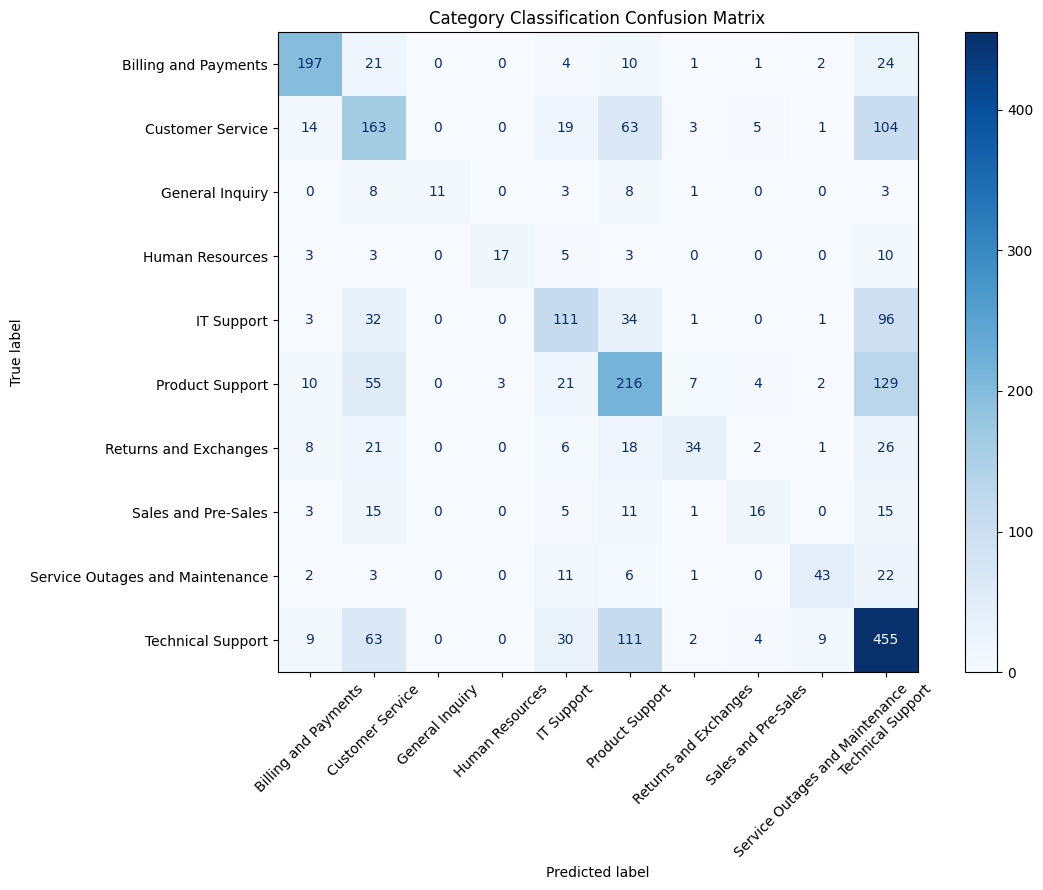

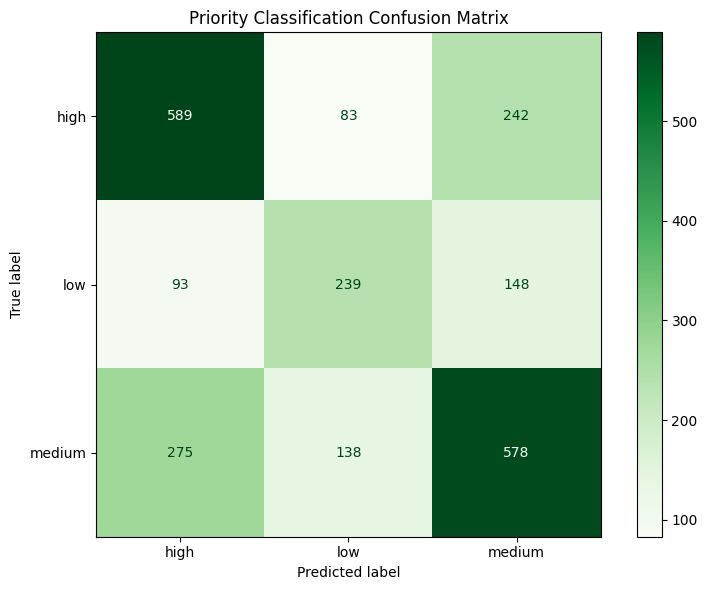

In [33]:

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Final category model: no class weighting
final_category_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=15000,
        ngram_range=(1, 2),
        min_df=2,
        sublinear_tf=True
    )),
    ("classifier", LinearSVC(
        class_weight=None,
        random_state=42
    ))
])

# Final priority model: balanced class weighting
final_priority_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=15000,
        ngram_range=(1, 2),
        min_df=2,
        sublinear_tf=True
    )),
    ("classifier", LinearSVC(
        class_weight="balanced",
        random_state=42
    ))
])

# Train final selected models
final_category_model.fit(X_train_cat, y_train_cat)
final_priority_model.fit(X_train_pri, y_train_pri)

# Predictions
final_category_predictions = final_category_model.predict(X_test_cat)
final_priority_predictions = final_priority_model.predict(X_test_pri)

# Category classification report
print("FINAL CATEGORY CLASSIFICATION REPORT")
print(classification_report(
    y_test_cat,
    final_category_predictions,
    zero_division=0
))

# Priority classification report
print("\nFINAL PRIORITY CLASSIFICATION REPORT")
print(classification_report(
    y_test_pri,
    final_priority_predictions,
    zero_division=0
))

# Category confusion matrix
fig, ax = plt.subplots(figsize=(12, 9))
ConfusionMatrixDisplay.from_predictions(
    y_test_cat,
    final_category_predictions,
    xticks_rotation=45,
    cmap="Blues",
    ax=ax
)
ax.set_title("Category Classification Confusion Matrix")
plt.tight_layout()
plt.show()

# Priority confusion matrix
fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test_pri,
    final_priority_predictions,
    xticks_rotation=0,
    cmap="Greens",
    ax=ax
)
ax.set_title("Priority Classification Confusion Matrix")
plt.tight_layout()
plt.show()


In [35]:
from sklearn.metrics import confusion_matrix
import pandas as pd

# Category confusion matrix
category_cm = confusion_matrix(
    y_test_cat,
    final_category_predictions,
    labels=final_category_model.classes_
)

print("CATEGORY CONFUSION MATRIX")
display(pd.DataFrame(
    category_cm,
    index=final_category_model.classes_,
    columns=final_category_model.classes_
))

# Priority confusion matrix
priority_cm = confusion_matrix(
    y_test_pri,
    final_priority_predictions,
    labels=final_priority_model.classes_
)

print("PRIORITY CONFUSION MATRIX")
display(pd.DataFrame(
    priority_cm,
    index=final_priority_model.classes_,
    columns=final_priority_model.classes_
))

CATEGORY CONFUSION MATRIX


,Billing and Payments,Customer Service,General Inquiry,Human Resources,IT Support,Product Support,Returns and Exchanges,Sales and Pre-Sales,Service Outages and Maintenance,Technical Support
Billing and Payments,197,21,0,0,4,10,1,1,2,24
Customer Service,14,163,0,0,19,63,3,5,1,104
General Inquiry,0,8,11,0,3,8,1,0,0,3
Human Resources,3,3,0,17,5,3,0,0,0,10
IT Support,3,32,0,0,111,34,1,0,1,96
Product Support,10,55,0,3,21,216,7,4,2,129
Returns and Exchanges,8,21,0,0,6,18,34,2,1,26
Sales and Pre-Sales,3,15,0,0,5,11,1,16,0,15
Service Outages and Maintenance,2,3,0,0,11,6,1,0,43,22
Technical Support,9,63,0,0,30,111,2,4,9,455


PRIORITY CONFUSION MATRIX


,high,low,medium
high,589,83,242
low,93,239,148
medium,275,138,578


In [37]:
import os
import joblib

# Create a folder for the models
os.makedirs("models", exist_ok=True)

# Save category classification model
joblib.dump(
    final_category_model,
    "models/category_classifier.joblib"
)

# Save priority classification model
joblib.dump(
    final_priority_model,
    "models/priority_classifier.joblib"
)

print("Both models have been saved successfully!")

print("Saved files:")
print(os.listdir("models"))

Both models have been saved successfully!
Saved files:
['category_classifier.joblib', 'priority_classifier.joblib']


In [39]:
import joblib

# Load the saved models
category_model = joblib.load("models/category_classifier.joblib")
priority_model = joblib.load("models/priority_classifier.joblib")

# Create a new sample support ticket
new_ticket = [
    "Subject: Cannot access my account. "
    "Body: I am unable to log into my account because "
    "the system keeps showing an authentication error."
]

# Predict category and priority
predicted_category = category_model.predict(new_ticket)
predicted_priority = priority_model.predict(new_ticket)

# Display predictions
print("NEW SUPPORT TICKET PREDICTION")
print("--------------------------------")
print("Ticket:", new_ticket[0])
print("Predicted Category:", predicted_category[0])
print("Predicted Priority:", predicted_priority[0])

NEW SUPPORT TICKET PREDICTION
--------------------------------
Ticket: Subject: Cannot access my account. Body: I am unable to log into my account because the system keeps showing an authentication error.
Predicted Category: Billing and Payments
Predicted Priority: medium


In [40]:

import pandas as pd

file_path = "/content/dataset-tickets-multi-lang-4-20k.csv"

df = pd.read_csv(file_path)

print("DATASET LOADED SUCCESSFULLY")
print("\nDataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 records:")
display(df.head())


DATASET LOADED SUCCESSFULLY

Dataset shape: (20000, 15)

Column names:
['subject', 'body', 'answer', 'type', 'queue', 'priority', 'language', 'tag_1', 'tag_2', 'tag_3', 'tag_4', 'tag_5', 'tag_6', 'tag_7', 'tag_8']

First 5 records:


,subject,body,answer,type,queue,priority,language,tag_1,tag_2,tag_3,tag_4,tag_5,tag_6,tag_7,tag_8
0,Unvorhergesehener Absturz der Datenanalyse-Plattform,"Die Datenanalyse-Plattform brach unerwartet ab, da die Speicheroberfläche zu gering war. Ich habe versucht, Laravel 8 und meinen MacBook Pro neu z...","Ich werde Ihnen bei der Lösung des Problems helfen, indem die Datenanalyse-Plattform neu gestartet wird. Bitte bereiten Sie spezifische Informatio...",Incident,General Inquiry,low,de,Crash,Technical,Bug,Hardware,Resolution,Outage,Documentation,NaN
1,Customer Support Inquiry,Seeking information on digital strategies that can aid in brand growth and details on the available services. Looking forward to learning more to ...,"We offer a variety of digital strategies and services to boost brand growth, including social media management and marketing. Let's discuss furthe...",Request,Customer Service,medium,en,Feedback,Sales,IT,Tech Support,NaN,NaN,NaN,NaN
2,Data Analytics for Investment,I am contacting you to request information on data analytics tools that can be utilized with the Eclipse IDE for enhancing investment optimization...,"I am here to assist you with data analytics tools for investment optimization. Please provide more details on your requirements, and I will sugges...",Request,Customer Service,medium,en,Technical,Product,Guidance,Documentation,Performance,Feature,NaN,NaN
3,Krankenhaus-Dienstleistung-Problem,Ein Medien-Daten-Sperrverhalten trat aufgrund unerlaubten Zugriffes auf. Eine schwache Passwortauswahl ist wahrscheinlich die Ursache. Nach dem Ve...,Zurück zur E-Mail-Beschwerde über den Sperrversuch auf Grund unerlaubten Zugriffes bei den Medien-Daten. Leider bleibt das Problem trotz des Passw...,Incident,Customer Service,high,de,Security,Breach,Login,Maintenance,Incident,Resolution,Feedback,NaN
4,Security,"Dear Customer Support, I am reaching out to inquire about the security protocols you have in place to protect medical data. As a valued customer, ...","Dear [name], we take the security of medical data very seriously and have implemented strong security measures to protect sensitive information. O...",Request,Customer Service,medium,en,Security,Customer,Compliance,Breach,Documentation,Guidance,NaN,NaN
